In [64]:
#replaced the matrix and linear equation analysis.py file
import numpy as np

In [65]:
def LU(A):

    '''Do the guassian elemenation'''
    '''in fact, this is also called doolittle's algorithm'''
    
    U=A.copy()
    dim=U.shape[0]
    det=1
    L=np.eye(dim,dtype=float)
    for i in range(1,dim):
        det*=U[i-1,i-1]
        L[i:,i-1]=U[i:,i-1]/U[i-1,i-1]
        U[i:,:]-=np.outer(L[i:,i-1],U[i-1,:])
    return U,L,det

In [66]:
#input depend on question and user
A=np.array([[2,1,0,0],[1,2,1,0],[0,1,3,2],[0,0,2,3]],
            dtype=float)

dim=A.shape[0]
f=np.array([0,0,0,0],dtype=float)#constant term

In [67]:
U,L,det=LU(np.block([A]))
print('determinant= ',det)
print(' ')
print('the upper triangle,as well as the REF=\n',U) # same as the REF of A
print(' ')
print('the lower triangle=\n',L)
UU,LL,detdet=LU(np.block([A.T@A]))
#print(L@U)

determinant=  7.0
 
the upper triangle,as well as the REF=
 [[2.         1.         0.         0.        ]
 [0.         1.5        1.         0.        ]
 [0.         0.         2.33333333 2.        ]
 [0.         0.         0.         1.28571429]]
 
the lower triangle=
 [[1.         0.         0.         0.        ]
 [0.5        1.         0.         0.        ]
 [0.         0.66666667 1.         0.        ]
 [0.         0.         0.85714286 1.        ]]


In [68]:
# solving sys of lin eq by for sub
# first solve Ly=f, then Ux=y. 
# comp cost= O(n^2)

y=np.zeros_like(f)
y[0]=f[0]/L[0,0]
for i in range(1,dim):
    f[i]-=y[:i]@L[i,:i]
    y[i]=f[i]/L[i,i]

x=np.zeros_like(f)
x[-1]=y[-1]/U[-1,-1]
for i in range(dim-2,-1,-1):
    y[i]-=x[i+1:]@U[i,i+1:]
    x[i]=y[i]/U[i,i]

print('sol=',x)

sol= [0. 0. 0. 0.]


In [69]:
#some norms (including different non-induced norms)
n1=[]
for i in range(A.shape[0]):
    ans=0
    for j in range(A.shape[1]):
        ans+=abs(A[i,j])
    n1.append(ans)
n1=max(n1)
print('1-norm=',n1)

rho=np.max(np.diag(U))
print('spectral radius=',rho)

inter=A.T@A
n2=np.sqrt(np.max(np.diag(UU)))
print('2-norm=',n2)


ninf=[]
for j in range(A.shape[1]):
    ans=0
    for i in range(A.shape[0]):
        ans+=abs(A[i,j])
    ninf.append(ans)
ninf=max(ninf)
print('infinite norm=',ninf)

1-norm= 6.0
spectral radius= 2.3333333333333335
2-norm= 2.7386127875258306
infinite norm= 6.0


In [70]:
# the cholesky decomposition, note that cholesky is only valid for symmetric positive def mat.
# it is very common to see L.T!=U if the matrix does not satisfy the cond.
def cholesky(A):
    U,L,det=LU(A)
    dim=U.shape[0]
    D=np.diag(np.sqrt(np.diag(U)))
    for i in range(dim):
        U[i,:]/=np.diag(U)[i]
    L=L@D
    U=D@U
    return L,D,U

In [71]:
L,D,U=cholesky(A)
print(L)
print('check:\n',L@L.T)

[[1.41421356 0.         0.         0.        ]
 [0.70710678 1.22474487 0.         0.        ]
 [0.         0.81649658 1.52752523 0.        ]
 [0.         0.         1.30930734 1.13389342]]
check:
 [[2. 1. 0. 0.]
 [1. 2. 1. 0.]
 [0. 1. 3. 2.]
 [0. 0. 2. 3.]]


In [72]:
# crout's factoisation, idk if it is the correct one as crout proposed
def crout(A):
    U,L,det=LU(A)
    dim=U.shape[0]
    D=np.diag(np.diag(U))
    for i in range(dim):
        U[i,:]/=np.diag(U)[i]
    L=L@D
    return L,U

In [73]:
L,U=crout(A)
print(L)
print(' ')
print(U)
print(' ')
print(L@U)

[[2.         0.         0.         0.        ]
 [1.         1.5        0.         0.        ]
 [0.         1.         2.33333333 0.        ]
 [0.         0.         2.         1.28571429]]
 
[[1.         0.5        0.         0.        ]
 [0.         1.         0.66666667 0.        ]
 [0.         0.         1.         0.85714286]
 [0.         0.         0.         1.        ]]
 
[[2. 1. 0. 0.]
 [1. 2. 1. 0.]
 [0. 1. 3. 2.]
 [0. 0. 2. 3.]]


In [74]:
def RREF(A):
    U=LU(A)[0]
    dim=U.shape[0]
    
    for i in range(dim-1,0,-1):
        for j in range(i):
            U[j,:]-=(U[j,i]/U[i,i])*U[i,:]
            U[j,:]/=U[j,j]
            #print(U)
    U[dim-1,:]/=U[dim-1,dim-1]
    return U

In [75]:
R=RREF(np.block([U,np.eye(dim)]))
print(R)

[[ 1.          0.          0.          0.          1.         -0.5
   0.33333333 -0.28571429]
 [ 0.          1.          0.          0.          0.          1.
  -0.66666667  0.57142857]
 [ 0.          0.          1.          0.          0.          0.
   1.         -0.85714286]
 [ 0.          0.          0.          1.          0.          0.
   0.          1.        ]]


In [76]:
Ainv=RREF(np.block([A,np.eye(dim)]))[:,dim:]
Ainv

array([[ 0.77777778, -0.55555556,  0.33333333, -0.22222222],
       [-0.55555556,  1.11111111, -0.66666667,  0.44444444],
       [ 0.33333333, -0.66666667,  1.        , -0.66666667],
       [-0.22222222,  0.44444444, -0.66666667,  0.77777778]])

In [77]:
Ainv.dot(f)

array([0., 0., 0., 0.])

In [78]:
# some special matrices, 
# the inputs are the information that we only need when constructing the matrices

def tridiag(dim,l,m,u):
    '''dimension, lower diag, middle diag, upper diag'''
    T=np.zeros((dim,dim))
    for i in range(dim):
        T[i,i]=m
        if i>0:
            T[i,i-1]=l
        if i<dim-1:
            T[i,i+1]=u
    return T

def DFT(dim):
    '''the dst matrix is just the negative of 1st quater of this matrix,
    and the inverse of it is the 1st quater of this matrix'''
    
    w=np.exp(-2j*np.pi/dim)
    D=np.ones((dim,dim),dtype=complex)
    for i in range(dim):
        for j in range(dim):
            D[i,j]=w**(i*j)
    return D

def iDFT(dim):
    w=np.exp(2j*np.pi/dim)
    D=np.ones((dim,dim),dtype=complex)
    for i in range(dim):
        for j in range(dim):
            D[i,j]=w**(i*j)
    D/=dim
    return D

def circulant(vector): 
    vec=vector.copy()
    dim=len(vec)
    V=np.zeros((dim,dim))
    inter=tridiag(dim,0,0,1)
    inter[-1,0]=1
    V[0,:]=vec
    for i in range(1,dim):
        vec=vec.dot(inter)
        V[i,:]=vec
    return V

In [79]:
vec=np.array([1,0,0,0,0],dtype=float)
dim=vec.shape[0]
A=circulant(vec)
D=DFT(dim)
iD=iDFT(dim)
print(D)

[[ 1.        +0.j          1.        +0.j          1.        +0.j
   1.        +0.j          1.        +0.j        ]
 [ 1.        +0.j          0.30901699-0.95105652j -0.80901699-0.58778525j
  -0.80901699+0.58778525j  0.30901699+0.95105652j]
 [ 1.        +0.j         -0.80901699-0.58778525j  0.30901699+0.95105652j
   0.30901699-0.95105652j -0.80901699+0.58778525j]
 [ 1.        +0.j         -0.80901699+0.58778525j  0.30901699-0.95105652j
   0.30901699+0.95105652j -0.80901699-0.58778525j]
 [ 1.        +0.j          0.30901699+0.95105652j -0.80901699+0.58778525j
  -0.80901699-0.58778525j  0.30901699-0.95105652j]]


[ 0.00146311 -0.00438932  0.00397129]
[ 0.3953165  -0.04749388  0.99683631]
[-0.29583784 -0.04093436  1.68891505]


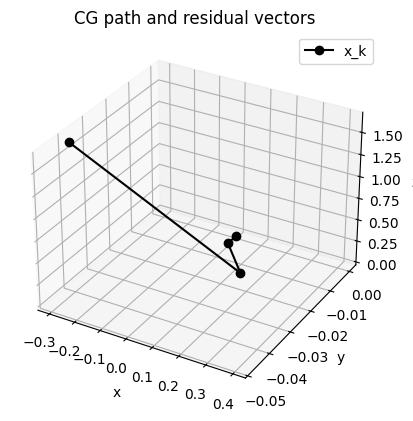

In [80]:
# in this cell, the geometric flow of CG method is illustrated
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

X=np.array([[4,100,3],[4,-1,3],[-2,1,2]],
            dtype=float)
A=np.dot(X.T,X)
x=np.array([0,0,0],dtype=float)
f=np.array([7,-21,19],dtype=float)
r=f-(X.T@(X@x))
p=r.copy()
it=0
maxit=100

xpts=np.linspace(-2,2,41)
ypts=np.linspace(-2,2,41)
zpts=np.linspace(-2,2,41)
xx,yy,zz=np.meshgrid(xpts,ypts,zpts,indexing='ij')

fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')

# Store iterates so the curve is drawn in the true iteration order
path=[x.copy()]
res=[r.copy()]

while True:
    it+=1
    inter=X@p #these 2 intermediate steps are used to accelerate
    inter2=X.T@inter #the code and reduce memory use if A is too large
    a=np.inner(r,r)/(np.dot(p,inter2))
    x+=a*p
    path.append(x.copy())
    print(x)
    r_new=r-a*inter2
    res.append(r_new.copy())
    if np.max(abs(r_new))<1e-4 or it>=maxit:
        break
    else:
        b=np.inner(r_new,r_new)/np.inner(r,r)
        p=r_new+b*p
        r=r_new

path=np.array(path)
res=np.array(res)
ax.plot(path[:,0],path[:,1],path[:,2],color='black',marker='o',label='x_k')
#ax.plot(res[:,0],res[:,1],res[:,2],color='red',marker='x',label='r_k')
ax.legend()

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('CG path and residual vectors')
plt.show()

In [81]:
# other than CG, some iterative methods

def jacobi(A,x,f):
    A=A.copy()
    dim=A.shape[0]
    for i in range(dim):
        x[i]=(f[i]-np.dot(A[i,:],x)+A[i,i]*x[i])/A[i,i]
    return x

def GS(A,x,f):
    A=A.copy()
    dim=A.shape[0]
    for i in range(dim):
        x[i]=(f[i]-np.dot(A[i,:],x)+A[i,i]*x[i])/A[i,i]
    return x

def SOR(A,x,w,f):
    x_new=GS(A,x,f)
    x=w*x_new+(1-w)*x
    return x

In [82]:
# orthogonalization

A=np.array([[0.4,0,-0.4]/np.sqrt(9.2),[-2.4,4,7.8]/np.sqrt(79.8),[0,0,1]],
            dtype=float)

def orthonormal(A):
    A=A.copy()
    dim=A.shape[0]
    A[:,0]/=np.linalg.norm(A[:,0])
    for i in range(1,dim):
        for j in range(i):
            A[:,i]-=np.dot(A[:,j],A[:,i])*A[:,j]
        A[:,i]/=np.linalg.norm(A[:,i])
    return A

A=orthonormal(A)
print(A)

[[ 4.40636567e-01  8.97685589e-01 -2.77555756e-17]
 [-8.97685589e-01  4.40636567e-01 -1.38777878e-17]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [83]:
# library diagonalization
A=np.array([[35,34],[34,54]],dtype=float)
eigvals,eigvecs=np.linalg.eig(A)
print('eigenvals=',eigvals)
print(' ')
print('eigvecs=',eigvecs)

eigenvals= [ 9.19773378 79.80226622]
 
eigvecs= [[-0.79658789 -0.60452273]
 [ 0.60452273 -0.79658789]]


In [84]:
# the SVD factorisation, which is the general eigenvalue decomposition
# SVD gives if A is a n*m matrix, then P is n*n, D is n*m, Q is m*m, and A=P@D@Q.T

A=np.array([[1,2],[3,4],[5,6]],dtype=float)
P,D,Q=np.linalg.svd(A)
Dmat=np.zeros_like(A)
Dmat[:D.shape[0],:D.shape[0]]=np.diag(D)
print('P=',P)
print(' ')
print('D=',Dmat)
print(' ')
print('Q=',Q)

P= [[-0.2298477   0.88346102  0.40824829]
 [-0.52474482  0.24078249 -0.81649658]
 [-0.81964194 -0.40189603  0.40824829]]
 
D= [[9.52551809 0.        ]
 [0.         0.51430058]
 [0.         0.        ]]
 
Q= [[-0.61962948 -0.78489445]
 [-0.78489445  0.61962948]]
